In [2]:
from common import *

In [3]:
compute = False

### Forward mapping

In [4]:
def motif_name(df):
    zips = zip(df['inner_resnames'], df['inner_resids'], df['inner_names'])
    
    motifs = [
        ",".join(f"{rn}{ri}{n}" for rn, ri, n in zip(rns, ris, ns))
        for rns, ris, ns in zips
    ]
    
    return [
        f"{m}-{mgrna}" if mgrna else m 
        for m, mgrna in zip(motifs, df['mgrna'])
    ]

By motif:

In [5]:
best_tempfactors = pd.read_csv('best_tempfactors.csv', names=['sim', 'align', 'mask', 'tempfactor'], skiprows=1).set_index(['sim', 'align', 'mask'])

In [6]:
best_tempfactors.index.get_level_values(level=2).unique()

Index(['All', 'Core', 'Core Phosphates', 'All (Shell only)',
       'Core (Shell only)', 'Core Phosphates (Shell only)'],
      dtype='object', name='mask')

In [7]:
# Collect all motifs summaries

res = pd.DataFrame()

# Replex
systems = ['7ez0', '7ez0_noion']
for sys in systems:
    _res = pd.read_parquet(PROJECT_DIR / f'replex/{sys}/mMg_tip3p/MG_motifs_summary_lambda0.parquet').assign(sim=f'replex_{sys}_mMg_tip3p', method='replex', sys=sys, forcefield='mMg_tip3p')
    res = pd.concat([res, _res])
# Replex (by replicate)
for sys in systems:
    for rep in range(2):
        _res = pd.read_parquet(PROJECT_DIR / f'replex/{sys}/mMg_tip3p/replicate{rep}/MG_motifs_summary_lambda0.parquet').assign(sim=f'replex_{sys}_mMg_tip3p_{rep}', method='replex', sys=f"{sys}_{rep}", forcefield='mMg_tip3p')
        res = pd.concat([res, _res])

# PlainMD
systems = ['7ez0', '7ez0_noion']
forcefields = ['mMg_tip3p', 'nMg_tip3p', 'nMg_tip3p_soft']
for sys, ff in itertools.product(systems, forcefields):
    try:
        path = PROJECT_DIR / f'plain_md/{sys}/{ff}/MG_motifs_summary.parquet'
        _res = pd.read_parquet(path).assign(sim=f'plain_md_{sys}_{ff}', method='plain_md', sys=sys, forcefield=ff)
    except FileNotFoundError:
        print(path)
        pass
    else:
        res = pd.concat([res, _res])

# References
_res = pd.read_parquet(PROJECT_DIR / f'structures/7ez0/mMg_tip3p/MG_motifs_summary.parquet').assign(sim=f'7ez0', method='pdb', sys='7ez0', forcefield='7ez0')
res = pd.concat([res, _res])

forcefields = ['mMg_tip3p', 'nMg_tip3p']
for sys, ff in itertools.product(systems, forcefields):
    _res = pd.read_parquet(PROJECT_DIR / f'structures/{sys}/{ff}/MG_motifs_equil_summary.parquet').assign(sim=f'equil_{sys}_{ff}', method='equil', sys=sys, forcefield=ff)
    res = pd.concat([res, _res])

_res = pd.read_parquet(PROJECT_DIR / f'structures/9cbu/MG_motifs_summary.parquet').assign(sim=f'9cbu', method='pdb', sys='9cbu', forcefield='pdb')
res = pd.concat([res, _res])
res = res.drop(index="").reset_index()
res['inner_labels'] = res.apply(lambda x: [f"{resname}{resid}{name}" for resname, resid, name in zip(x['inner_resnames'], x['inner_resids'], x['inner_names'])], axis=1)
motif_summary = res.copy()
motif_summary['motif_max_p'] = motif_summary.groupby('motif')['p'].transform('max')
motif_summary = motif_summary.query('motif_max_p > 0.05')



/net/sbp/sbpstore2/olanguin/mg_sampling/plain_md/7ez0_noion/nMg_tip3p_soft/MG_motifs_summary.parquet


In [8]:
device = 'cuda'
chunk_size = 8192

methods = ['replex', 'plain_md']
systems = ['7ez0', '7ez0_noion']
forcefields = ['mMg_tip3p', 'nMg_tip3p']
replicates = [0, 1]
repids = range(8)
alignments = ['local', 'global']

# methods = ['plain_md']
# systems = ['7ez0_noion']
# forcefields = ['mMg_tip3p']
# replicates = [0, 1]
# repids = range(8)
# alignments = ['local', 'global']

def run(method, sys, ff, rep, repid, align):

    sim = f"{method}_{sys}_{ff}"

    path = PROJECT_DIR / f'{method}/{sys}/{ff}/replicate{rep}/rep{repid+rep*8:02d}'
    if not path.exists():
        return

    outpath = PROJECT_DIR / f'density/{sim}/{align}/individual'
    outpath.mkdir(exist_ok=True, parents=True)
    outfile = outpath / f'replicate{rep}_repid{repid:02d}.pkl'
    if outfile.exists():
        print(outfile, "already exists")
        return

    # if method == 'plain_md':
    #     motifs_summary = pd.read_parquet(path / '../../MG_motifs_summary.parquet')
    # else:
    #     motifs_summary = pd.read_parquet(path / '../../MG_motifs_summary_lambda0.parquet')
    motif_selection = motif_summary.drop_duplicates(subset='motif').reset_index()

    columns = ['frame', 'time', 'inner_names', 'inner_resids', 'inner_resnames', 'mgrna']
    motifs = pd.read_parquet(path / 'MG_motifs.parquet', columns=columns)
    # Subsampling
    if method == 'plain_md':
        motifs = motifs.query("frame % 24 == 0")
    motifs['motif'] = motif_name(motifs)
    if method == 'replex':
        colvar = read_plumed(path / f'bias.COLVAR.{repid}')
        colvar['time'] = colvar['time'].astype(int)
        motifs['reptemp'] = colvar.set_index('time').loc[motifs['time'].astype(int), 'bias.index'].astype(int).values
    else:
        motifs['reptemp'] = 0

    all_frames = motifs.loc[motifs['reptemp'] == 0, 'frame'].unique()

    ref_hmap_A, ref_hmap_B = Grid(PROJECT_DIR / "density/emd_42499_Con2-2.2A_half_A.mrc"), Grid(PROJECT_DIR / "density/emd_42499_Con2-2.2A_half_B.mrc")
    ref_map = 0.5 * (ref_hmap_A + ref_hmap_B)
    grid_params = ref_map.grid_params

    ref = mda.Universe(PROJECT_DIR / "structures/9CBU_fixed.pdb")
    ref_rna = ref.select_atoms("nucleic and not type H and not (resid 22 and name P OP1 OP2)")

    u = mda.Universe(
        path / f'input.gro',
        path / f'run.xtc',
    )
    standardize_names(u)
    best_tempfactor = best_tempfactors.loc[sim, align, 'Core Phosphates (Shell only)']
    u.add_TopologyAttr('tempfactors', np.full(shape=len(u.atoms), fill_value=best_tempfactor))
    rna = u.select_atoms("nucleic and not type H and not (resid 22 and name P OP1 OP2)")
    mob_out = u.select_atoms('not type H')

    def prepare(row):
        row['frames_present'] = np.intersect1d(
            motifs.loc[(motifs['reptemp'] == 0) & (motifs['motif'] == row['motif']), 'frame'].unique(),
            all_frames,
            assume_unique=True,
        )
        row['frames_absent'] = np.setdiff1d(all_frames, row['frames_present'], assume_unique=True)

        # Prepare selections of motif atoms
        row['ref_ag'] = ref_rna.select_atoms(*[
                f"name {name} and resid {resid} and resname {resname}" 
                for name, resid, resname in zip(row['inner_names'], row['inner_resids'], row['inner_resnames'])
            ])
        row['mob_ag'] = rna.select_atoms(*[
                f"name {name} and resid {resid} and resname {resname}" 
                for name, resid, resname in zip(row['inner_names'], row['inner_resids'], row['inner_resnames'])
            ])
        # Prepare updating selections for output
        row['out_ag'] = mob_out.select_atoms(
                "group mob_ag or (around 10 group mob_ag)",
                mob_ag=row['mob_ag'],
                updating=True,
            )
        # Grid mask
        row['vox_indices'] = voxels_around(row['ref_ag'], 6, grid_params)

        # Prepare selections for alignment of ref and mobile
        if align == 'local':
            # Local neighborhood
            row['ref_align_ag'] = ref_rna.select_atoms("(around 10 group ref_ag) or group ref_ag", ref_ag=row['ref_ag'])
            row['mob_align_ag'] = rna.select_atoms(*[
                    f"name {a.name} and resid {a.resid} and resname {a.resname}"
                    for a in row['ref_align_ag']
                ])
            check_alignable(row['mob_align_ag'], row['ref_align_ag'])

        row['map_present'] = SparseGrid(
            data=np.zeros_like(row['vox_indices']),
            vox_indices=row['vox_indices'],
            **grid_params,
        )
        row['map_absent'] = SparseGrid(
            data=np.zeros_like(row['vox_indices']),
            vox_indices=row['vox_indices'],
            **grid_params,
        )
        return row

    motif_selection = motif_selection.apply(prepare, axis='columns')

    # All RNA
    if align == 'global':
        ref_align_ag = reorder_residue_atoms(ref_rna)
        mob_align_ag = reorder_residue_atoms(rna)
        check_alignable(mob_align_ag, ref_align_ag)


    mob_ag_all = motif_selection['mob_ag'].sum().asunique()

    for ts in tqdm(u.trajectory[all_frames]):
        # Make RNA whole
        unwrap_sequential(rna)

        # Combining multiple wrap + align messes up relative positions,
        # we have to restore the initial frame
        pos = mob_out.positions.copy()
        for i in motif_selection.index:
            # Wrap solvent around motifs
            wrap_around(motif_selection.loc[i, 'out_ag'], motif_selection.loc[i, 'mob_ag'].center_of_mass())
            # Alignment
            if align == 'local':
                alignto(motif_selection.loc[i, 'mob_align_ag'], motif_selection.loc[i, 'ref_align_ag'], subselection=motif_selection.loc[i, 'out_ag'])
            else:
                alignto(mob_align_ag, ref_align_ag, subselection=motif_selection.loc[i, 'out_ag'])
            # Get map
            map_ = atomgroup_to_map(
                motif_selection.loc[i, 'out_ag'],
                shape=grid_params['shape'],
                delta=grid_params['delta'],
                origin=grid_params['origin'],
                vox_indices=motif_selection.loc[i, 'vox_indices'],
                cutoff=4.0,
                device=device,
                chunk_size=chunk_size,
            )
            # Add it to the total
            if ts.frame in motif_selection.loc[i, 'frames_present']:
                motif_selection.loc[i, 'map_present'] += map_ / len(motif_selection.loc[i, 'frames_present'])
            elif ts.frame in motif_selection.loc[i, 'frames_absent']:
                motif_selection.loc[i, 'map_absent'] += map_ / len(motif_selection.loc[i, 'frames_absent'])
            # Restore coordinates
            mob_out.positions = pos
        
    df = motif_selection[['motif', 'frames_present', 'frames_absent', 'map_present', 'map_absent']]
    df.to_pickle(outfile)

In [9]:
if compute:
    from dask.distributed import Client
    from dask import delayed, compute

    n_workers = 6
    tasks = []
    for args in itertools.product(methods, systems, forcefields, replicates, repids, alignments):
        tasks.append(
            delayed(run)(*args)
        )

    with Client(threads_per_worker=1, n_workers=n_workers) as client:
        print(f"Computing {len(tasks)} tasks…", flush=True)
        print("Dashboard:", client.dashboard_link)
        compute(*tasks)

### Evaluation

In [10]:
df = []
for method, sys, ff, rep, repid, alignment in itertools.product(methods, systems, forcefields, replicates, repids, alignments):
    outpath = PROJECT_DIR / f'density/{method}_{sys}_{ff}/{alignment}/individual/replicate{rep}_repid{repid:02d}.pkl'
    if not outpath.exists():
        continue
    df.append(pd.read_pickle(outpath).assign(sim=f'{method}_{sys}_{ff}', method=method, system=sys, forcefield=ff, replicate=rep, repid=repid, alignment=alignment))
df = pd.concat(df)
df.head()

,motif,frames_present,frames_absent,map_present,map_absent,sim,method,system,forcefield,replicate,repid,alignment
0,A103OP1-Oph,"[719, 856, 862, 865, 874, 875, 881, 891, 892, ...","[0, 92, 100, 140, 148, 153, 156, 158, 160, 166...",<mg_sampling.density.grid.SparseGrid object at...,<mg_sampling.density.grid.SparseGrid object at...,replex_7ez0_mMg_tip3p,replex,7ez0,mMg_tip3p,0,0,local
1,A103OP2-Oph,"[92, 100, 140, 148, 153, 156, 158, 160, 166, 1...","[0, 439, 476, 533, 540, 549, 584, 606, 643, 71...",<mg_sampling.density.grid.SparseGrid object at...,<mg_sampling.density.grid.SparseGrid object at...,replex_7ez0_mMg_tip3p,replex,7ez0,mMg_tip3p,0,0,local
2,A104OP1-Oph,[],"[0, 92, 100, 140, 148, 153, 156, 158, 160, 166...",<mg_sampling.density.grid.SparseGrid object at...,<mg_sampling.density.grid.SparseGrid object at...,replex_7ez0_mMg_tip3p,replex,7ez0,mMg_tip3p,0,0,local
3,A104OP2-Oph,"[140, 148, 153, 156, 158, 160, 166, 168, 171, ...","[0, 92, 100, 172, 174, 178, 179, 181, 190, 191...",<mg_sampling.density.grid.SparseGrid object at...,<mg_sampling.density.grid.SparseGrid object at...,replex_7ez0_mMg_tip3p,replex,7ez0,mMg_tip3p,0,0,local
4,A105OP1-Oph,[],"[0, 92, 100, 140, 148, 153, 156, 158, 160, 166...",<mg_sampling.density.grid.SparseGrid object at...,<mg_sampling.density.grid.SparseGrid object at...,replex_7ez0_mMg_tip3p,replex,7ez0,mMg_tip3p,0,0,local


In [11]:
df['sim'].unique()

array(['replex_7ez0_mMg_tip3p', 'replex_7ez0_noion_mMg_tip3p',
       'plain_md_7ez0_mMg_tip3p', 'plain_md_7ez0_nMg_tip3p',
       'plain_md_7ez0_noion_mMg_tip3p', 'plain_md_7ez0_noion_nMg_tip3p'],
      dtype=object)

In [12]:
def atom_latex_name(s):
    return f"\mathrm{{{s[0]}}}_\mathrm{{{s[1:]}}}"

MGRNA_LTX = {
    'Oph': "$\\text{O}_\\text{ph}$",
    'Ob': "$\\text{O}_\\text{b}$",
    'Or': "$\\text{O}_\\text{r}$",
    'Nb': "$\\text{N}_\\text{b}$",
    'cis': r"\textit{cis}",
    'trans': r"\textit{trans}",
    'fac': r"\textit{fac}",
    'mer': r"\textit{mer}",
    'Cis': r"\underline{Cis}",
    'Trans': r"\underline{Trans}",
}

def motif_latex_name(x):
    names = x['inner_names']
    resnames = x['inner_resnames']
    resids = x['inner_resids']
    mgrna = x['mgrna']
    for k,v in MGRNA_LTX.items():
        mgrna = mgrna.replace(k, v)
    motif = ",".join(
        f"$\\text{{{resname}}}^\\text{{{resid}}}_\\text{{{name}}}$"
        for resname, resid, name in zip(resnames, resids, names)
    )
    if x['mgrna']:
        motif = motif + '-' + mgrna
    return motif

MGRNA_MTX = {
    'Oph': "$\mathrm{O}_\mathrm{ph}$",
    'Ob': "$\mathrm{O}_\mathrm{b}$",
    'Or': "$\mathrm{O}_\mathrm{r}$",
    'Nb': "$\mathrm{N}_\mathrm{b}$",
    'cis': "$\mathit{cis}$",
    'trans': "$\mathit{trans}$",
    'fac': "$\mathit{fac}$",
    'mer': "$\mathit{mer}$",
    'Cis': "$\mathrm{Cis}$",
    'Trans': "$\mathrm{Trans}$",
}

def motif_mathtex_name(x):
    names = x['inner_names']
    resnames = x['inner_resnames']
    resids = x['inner_resids']
    mgrna = x['mgrna']
    for k,v in MGRNA_MTX.items():
        mgrna = mgrna.replace(k, v)
    motif = ",".join(
        f"$\mathrm{{{resname}}}^\mathrm{{{resid}}}_\mathrm{{{name}}}$"
        for resname, resid, name in zip(resnames, resids, names)
    )
    if x['mgrna']:
        motif = motif + '-' + mgrna
    return motif


In [13]:
motif_latex_names = motif_summary.drop_duplicates(subset='motif').set_index('motif').apply(motif_latex_name, axis=1)
motif_mathtex_names = motif_summary.drop_duplicates(subset='motif').set_index('motif').apply(motif_mathtex_name, axis=1)

In [14]:
f_range = np.linspace(0, 1, 21)
ref_hmap_A, ref_hmap_B = Grid(PROJECT_DIR / "density/emd_42499_Con2-2.2A_half_A.mrc"), Grid(PROJECT_DIR / "density/emd_42499_Con2-2.2A_half_B.mrc")

def get_cc(df, n_bootstrap=200):
    n_blocks = len(df)
    n_present = df['frames_present'].map(len).to_numpy()  # (n_blocks,)
    n_absent = df['frames_absent'].map(len).to_numpy()  # (n_blocks,)
    if n_present.sum() == 0 or n_absent.sum() == 0:
        return None

    maps_present = np.stack(df['map_present'].map(lambda x: x.data).to_numpy())  # (n_blocks, n_vox)
    maps_absent = np.stack(df['map_absent'].map(lambda x: x.data).to_numpy())  # (n_blocks, n_vox)
    vox_indices = df['map_present'].iloc[0].vox_indices  # (n_vox, )
    grid_params = df['map_present'].iloc[0].to_dense().grid_params
    ref_maps_sub = np.stack([ref_hmap_A.to_sparse(vox_indices=vox_indices).data, ref_hmap_B.to_sparse(vox_indices=vox_indices).data])  # (2, n_vox)

    map_present = np.average(maps_present, weights=n_present, axis=0)  # (n_vox,)
    map_absent = np.average(maps_absent, weights=n_absent, axis=0)  # (n_vox,)
    ref_map_sub = np.average(ref_maps_sub, axis=0)  # (n_vox,)
    cc = linregress(
        f_range[:, None] * map_present + (1 - f_range)[:, None] * map_absent,
        ref_map_sub,
        axis=-1,
    ).rvalue  # (n_frac,)
    
    best_f = f_range[np.argmax(cc)]

    # Error estimation with bayesian bootstrap

    w_block_bs = np.random.dirichlet(np.ones(n_blocks), n_bootstrap)  # (n_bootstrap, n_blocks)
    w_ref_bs = np.random.dirichlet(np.ones(2), n_bootstrap)  # (n_bootstrap, 2)
    map_present_bs = (maps_present * w_block_bs[:, :, None] * n_present[:, None]).sum(axis=1) / (w_block_bs * n_present).sum(axis=1, keepdims=True)  # (n_bootstrap, n_vox)
    map_absent_bs = (maps_absent * w_block_bs[:, :, None] * n_absent[:, None]).sum(axis=1) / (w_block_bs * n_absent).sum(axis=1, keepdims=True)  # (n_bootstrap, n_vox)
    ref_map_sub_bs = (ref_maps_sub * w_ref_bs[:, :, None]).sum(axis=1) / w_ref_bs.sum(axis=1, keepdims=True)  # (n_bootstrap, n_vox)
    cc_bs = linregress(
        f_range[:, None, None] * map_present_bs + (1 - f_range)[:, None, None] * map_absent_bs,
        ref_map_sub_bs,
        axis=-1,
    ).rvalue  # (n_frac, n_bootstrap)
    cc_mean = np.mean(cc_bs, axis=-1)  # (n_frac,)
    cc_low, cc_high = np.quantile(cc_bs, (0.025, 0.975), axis=-1)
    best_f_bs = f_range[np.argmax(cc_bs, axis=0)]  # (n_bootstrap,)
    best_f_mean = np.mean(best_f_bs)
    best_f_low, best_f_high = np.quantile(best_f_bs, (0.025, 0.975))

    return pd.Series({
        'map_present': SparseGrid(data=map_present, vox_indices=vox_indices, **grid_params),
        'map_absent': SparseGrid(data=map_absent, vox_indices=vox_indices, **grid_params),
        'cc': cc,
        'cc_mean': cc_mean,
        'cc_low': cc_low,
        'cc_high': cc_high,
        'best_f': best_f,
        'best_f_mean': best_f_mean,
        'best_f_low': best_f_low,
        'best_f_high': best_f_high,
    })

if compute:
    # Merge "system" together (7ez0, 7ez0_noion)
    result = df.groupby(['motif', 'method', 'forcefield', 'alignment']).apply(get_cc)
    result.to_pickle('individual_motif.pkl')
else:
    result = pd.read_pickle('individual_motif.pkl')

In [15]:
motif_mathtex_names

motif
A103OP1-Oph    $\mathrm{A}^\mathrm{103}_\mathrm{OP1}$-$\mathr...
A103OP2-Oph    $\mathrm{A}^\mathrm{103}_\mathrm{OP2}$-$\mathr...
A104OP1-Oph    $\mathrm{A}^\mathrm{104}_\mathrm{OP1}$-$\mathr...
A104OP2-Oph    $\mathrm{A}^\mathrm{104}_\mathrm{OP2}$-$\mathr...
A105OP1-Oph    $\mathrm{A}^\mathrm{105}_\mathrm{OP1}$-$\mathr...
                                     ...                        
G313O2'-Or     $\mathrm{G}^\mathrm{313}_\mathrm{O2'}$-$\mathr...
G96N7-Nb       $\mathrm{G}^\mathrm{96}_\mathrm{N7}$-$\mathrm{...
U277O4-Ob      $\mathrm{U}^\mathrm{277}_\mathrm{O4}$-$\mathrm...
U326O4-Ob      $\mathrm{U}^\mathrm{326}_\mathrm{O4}$-$\mathrm...
U33OP1-Oph     $\mathrm{U}^\mathrm{33}_\mathrm{OP1}$-$\mathrm...
Length: 653, dtype: object

How well do global and local alignment correlate?

In [16]:
def concordance_correlation_coefficient(y_true, y_pred):
    mu_x = np.mean(y_true)
    mu_y = np.mean(y_pred)
    
    var_x = np.var(y_true, ddof=1)
    var_y = np.var(y_pred, ddof=1)
    
    cov_xy = np.cov(y_true, y_pred)[0, 1]
    
    ccc = (2 * cov_xy) / (var_x + var_y + (mu_x - mu_y)**2)
    
    return ccc

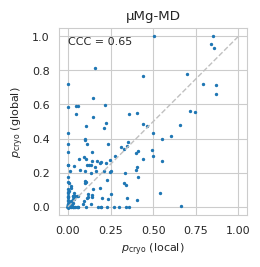

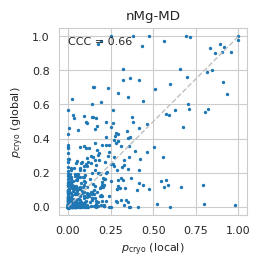

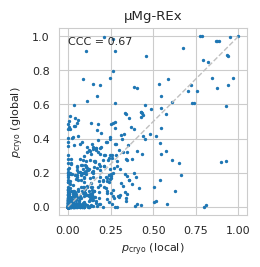

In [17]:
for (method, ff), group in result.groupby(['method', 'forcefield']):
    fig, ax = plt.subplots(figsize=(8.7*cm, 6.5*cm))
    x = group.loc[:, :, :, 'local']['best_f_mean'].dropna()
    y = group.loc[:, :, :, 'global']['best_f_mean'].dropna()
    ccc = concordance_correlation_coefficient(x, y)
    ax.plot([0,1], [0,1], color='silver', ls='dashed', lw=1)
    ax.scatter(
        x,
        y,
        s=2,
    )
    ax.set_aspect(1)
    ax.set_xlabel(r'$p_\mathrm{cryo}$ (local)')
    ax.set_ylabel(r'$p_\mathrm{cryo}$ (global)')
    ax.set_title(simlabels[f'{method}_7ez0_{ff}'])
    ax.text(0, 1, f"CCC = {ccc:.2f}", va='top')


How well do μMg an nMg correlate?

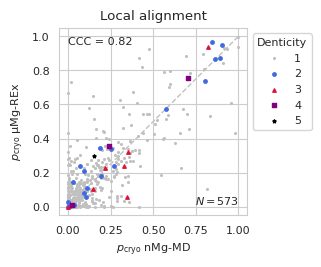

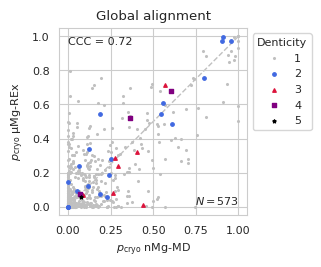

In [18]:
colors = {1: 'silver', 2: 'royalblue', 3: 'crimson', 4: 'purple', 5: 'black'}
markers = {1: '.', 2: 'o', 3: '^', 4: 's', 5: '*'}
for align in alignments:
    fig, ax = plt.subplots(figsize=(8.7*cm, 6.5*cm))
    x = result.loc[:, 'plain_md', 'nMg_tip3p', align]['best_f_mean'].dropna()
    y = result.loc[:, 'replex', 'mMg_tip3p', align]['best_f_mean'].dropna()
    x, y = x.align(y, join='inner')
    c = motif_summary.drop_duplicates(subset='motif').set_index('motif').loc[x.index, 'n_inner']
    ax.plot([0,1], [0,1], color='silver', ls='dashed', lw=1, zorder=-1)
    for n_inner in np.sort(c.unique()):
        ax.scatter(
            x.loc[c == n_inner],
            y.loc[c == n_inner],
            s=6,
            color=colors[n_inner],
            marker=markers[n_inner],
            label=n_inner,
        )

    ax.set_aspect(1)
    ax.set_xlabel(r'$p_\mathrm{cryo}$' + ' ' + simlabels['plain_md_7ez0_nMg_tip3p'])
    ax.set_ylabel(r'$p_\mathrm{cryo}$' + ' ' + simlabels['replex_7ez0_mMg_tip3p'])
    ax.set_title(align.capitalize() + ' alignment')
    ccc = concordance_correlation_coefficient(x, y)
    ax.text(0, 1, f'CCC = {ccc:.2f}', va='top')
    ax.text(1, 0, f'$N = {len(x)}$', va='bottom', ha='right')
    ax.legend(title='Denticity', bbox_to_anchor=(1, 1))
    fig.savefig(f'figures/nMg_mMg_cryo_{align}_agreement.pdf')

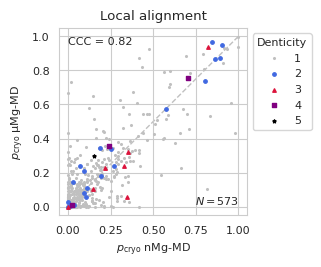

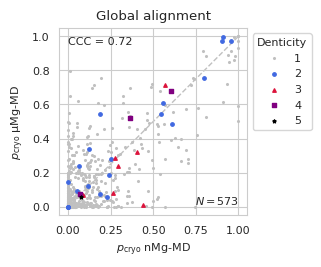

In [19]:
colors = {1: 'silver', 2: 'royalblue', 3: 'crimson', 4: 'purple', 5: 'black'}
markers = {1: '.', 2: 'o', 3: '^', 4: 's', 5: '*'}
for align in alignments:
    fig, ax = plt.subplots(figsize=(8.7*cm, 6.5*cm))
    x = result.loc[:, 'plain_md', 'nMg_tip3p', align]['best_f_mean'].dropna()
    y = result.loc[:, 'replex', 'mMg_tip3p', align]['best_f_mean'].dropna()
    x, y = x.align(y, join='inner')
    c = motif_summary.drop_duplicates(subset='motif').set_index('motif').loc[x.index, 'n_inner']
    ax.plot([0,1], [0,1], color='silver', ls='dashed', lw=1, zorder=-1)
    for n_inner in np.sort(c.unique()):
        ax.scatter(
            x.loc[c == n_inner],
            y.loc[c == n_inner],
            s=6,
            color=colors[n_inner],
            marker=markers[n_inner],
            label=n_inner,
        )

    ax.set_aspect(1)
    ax.set_xlabel(r'$p_\mathrm{cryo}$' + ' ' + simlabels['plain_md_7ez0_nMg_tip3p'])
    ax.set_ylabel(r'$p_\mathrm{cryo}$' + ' ' + simlabels['plain_md_7ez0_mMg_tip3p'])
    ax.set_title(align.capitalize() + ' alignment')
    ccc = concordance_correlation_coefficient(x, y)
    ax.text(0, 1, f'CCC = {ccc:.2f}', va='top')
    ax.text(1, 0, f'$N = {len(x)}$', va='bottom', ha='right')
    ax.legend(title='Denticity', bbox_to_anchor=(1, 1))
    fig.savefig(f'figures/mMg_REx_mMg_MD_cryo_{align}_agreement.pdf')

In [20]:
motif_summary.query("n_inner == 5")

,motif,p,p_low,p_high,n_block_obs,n_inner,inner_indices,inner_names,inner_resids,inner_resnames,stereo,mgrna,mg_indices,sim,method,sys,forcefield,inner_labels,motif_max_p
48,"A184OP1,A186OP1,A187OP2,A187H5'1,G188OP2-4OphX",0.001000,0.000417,0.001635,3,5,"[5226, 5289, 5323, 5326, 5356]","[OP1, OP1, OP2, H5'1, OP2]","[184, 186, 187, 187, 188]","[A, A, A, A, G]",,4OphX,[12445],replex_7ez0_mMg_tip3p,replex,7ez0,mMg_tip3p,"[A184OP1, A186OP1, A187OP2, A187H5'1, G188OP2]",0.0625
1617,"A184OP1,A186OP1,A187OP2,A187H5'1,G188OP2-4OphX",0.000500,0.000053,0.001171,1,5,"[5226, 5289, 5323, 5326, 5356]","[OP1, OP1, OP2, H5'1, OP2]","[184, 186, 187, 187, 188]","[A, A, A, A, G]",,4OphX,[12445],replex_7ez0_mMg_tip3p_0,replex,7ez0_0,mMg_tip3p,"[A184OP1, A186OP1, A187OP2, A187H5'1, G188OP2]",0.0625
2341,"A184OP1,A186OP1,A187OP2,A187H5'1,G188OP2-4OphX",0.001500,0.000724,0.002435,2,5,"[5226, 5289, 5323, 5326, 5356]","[OP1, OP1, OP2, H5'1, OP2]","[184, 186, 187, 187, 188]","[A, A, A, A, G]",,4OphX,[12445],replex_7ez0_mMg_tip3p_1,replex,7ez0_1,mMg_tip3p,"[A184OP1, A186OP1, A187OP2, A187H5'1, G188OP2]",0.0625
4516,"A184OP1,A186OP1,A187OP2,A187H5'1,G188OP2-4OphX",0.001479,0.001096,0.001778,8,5,"[5226, 5289, 5323, 5326, 5356]","[OP1, OP1, OP2, H5'1, OP2]","[184, 186, 187, 187, 188]","[A, A, A, A, G]",,4OphX,[12445],plain_md_7ez0_mMg_tip3p,plain_md,7ez0,mMg_tip3p,"[A184OP1, A186OP1, A187OP2, A187H5'1, G188OP2]",0.0625
4712,"A184OP1,A186OP1,A187OP2,A187H5'1,G188OP2-4OphX",0.001625,0.001098,0.002228,8,5,"[5226, 5289, 5323, 5326, 5356]","[OP1, OP1, OP2, H5'1, OP2]","[184, 186, 187, 187, 188]","[A, A, A, A, G]",,4OphX,[12445],plain_md_7ez0_nMg_tip3p,plain_md,7ez0,nMg_tip3p,"[A184OP1, A186OP1, A187OP2, A187H5'1, G188OP2]",0.0625
5395,"A184OP1,A186OP1,A187OP2,A187H5'1,G188OP2-4OphX",0.000771,0.000483,0.001201,8,5,"[5226, 5289, 5323, 5326, 5356]","[OP1, OP1, OP2, H5'1, OP2]","[184, 186, 187, 187, 188]","[A, A, A, A, G]",,4OphX,[12445],plain_md_7ez0_nMg_tip3p_soft,plain_md,7ez0,nMg_tip3p_soft,"[A184OP1, A186OP1, A187OP2, A187H5'1, G188OP2]",0.0625
6973,"A184OP1,A186OP1,A187OP2,A187H5'1,G188OP2-4OphX",0.062500,0.001901,0.184182,1,5,"[5226, 5289, 5323, 5326, 5356]","[OP1, OP1, OP2, H5'1, OP2]","[184, 186, 187, 187, 188]","[A, A, A, A, G]",,4OphX,[12445],equil_7ez0_mMg_tip3p,equil,7ez0,mMg_tip3p,"[A184OP1, A186OP1, A187OP2, A187H5'1, G188OP2]",0.0625
7022,"A184OP1,A186OP1,A187OP2,A187H5'1,G188OP2-4OphX",0.062500,0.001170,0.197741,1,5,"[5226, 5289, 5323, 5326, 5356]","[OP1, OP1, OP2, H5'1, OP2]","[184, 186, 187, 187, 188]","[A, A, A, A, G]",,4OphX,[12445],equil_7ez0_nMg_tip3p,equil,7ez0,nMg_tip3p,"[A184OP1, A186OP1, A187OP2, A187H5'1, G188OP2]",0.0625


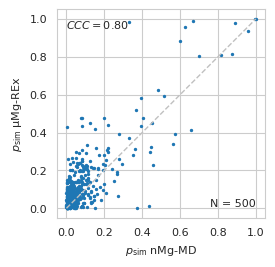

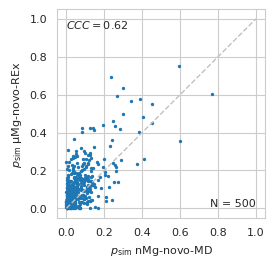

In [21]:
for sys in ['7ez0', '7ez0_noion']:
    fig, ax = plt.subplots(figsize=(8.7*cm, 6.5*cm))
    x = motif_summary.set_index(['motif', 'method', 'sys', 'forcefield']).loc[:, 'plain_md', sys, 'nMg_tip3p']['p'].dropna()
    y = motif_summary.set_index(['motif', 'method', 'sys', 'forcefield']).loc[:, 'replex', sys, 'mMg_tip3p']['p'].dropna()
    x, y = x.align(y, join='inner')
    ax.plot([0,1], [0,1], color='silver', ls='dashed', lw=1)
    ax.scatter(
        x,
        y,
        s=2,
    )
    ax.set_aspect(1)
    ax.set_xlabel(r'$p_\mathrm{sim}$' + ' ' + simlabels[f'plain_md_{sys}_nMg_tip3p'])
    ax.set_ylabel(r'$p_\mathrm{sim}$' + ' ' + simlabels[f'replex_{sys}_mMg_tip3p'])
    ccc = concordance_correlation_coefficient(x, y)
    ax.text(0, 1, f'$CCC = {ccc:.2f}$', va='top')
    ax.text(1, 0, f'N = {len(x)}', va='bottom', ha='right')

How well do simulation and CryoEM correlate?

In [22]:
result.head()

map_present  \
motif       method   forcefield alignment                                                      
A103OP1-Oph plain_md mMg_tip3p  global                                                   NaN   
                                local                                                    NaN   
                     nMg_tip3p  global     <mg_sampling.density.grid.SparseGrid object at...   
                                local      <mg_sampling.density.grid.SparseGrid object at...   
            replex   mMg_tip3p  global     <mg_sampling.density.grid.SparseGrid object at...   

                                                                                  map_absent  \
motif       method   forcefield alignment                                                      
A103OP1-Oph plain_md mMg_tip3p  global                                                   NaN   
                                local                                                    NaN   
                     nMg_tip3p  global     <mg_sampling.density.grid.SparseGrid object at...   
                                local      <mg_sampling.density.grid.SparseGrid object at...   
            replex   mMg_tip3p  global     <mg_sampling.density.grid.SparseGrid object at...   

                                                                                          cc  \
motif       method   forcefield alignment                                                      
A103OP1-Oph plain_md mMg_tip3p  global                                                   NaN   
                                local                                                    NaN   
                     nMg_tip3p  global     [0.5581910033061276, 0.5612326743520204, 0.564...   
                                local      [0.8565617278672243, 0.856997628287498, 0.8572...   
            replex   mMg_tip3p  global     [0.5509966312614897, 0.5542685217963964, 0.557...   

                                                                                     cc_mean  \
motif       method   forcefield alignment                                                      
A103OP1-Oph plain_md mMg_tip3p  global                                                   NaN   
                                local                                                    NaN   
                     nMg_tip3p  global     [0.5562177792942221, 0.5592374481911435, 0.562...   
                                local      [0.8530992159618749, 0.8535982462403991, 0.853...   
            replex   mMg_tip3p  global     [0.5487223756789769, 0.5517878219421966, 0.554...   

                                                                                      cc_low  \
motif       method   forcefield alignment                                                      
A103OP1-Oph plain_md mMg_tip3p  global                                                   NaN   
                                local                                                    NaN   
                     nMg_tip3p  global     [0.5318170163350103, 0.5352806785311303, 0.540...   
                                local      [0.8421468302008905, 0.8427522565483265, 0.843...   
            replex   mMg_tip3p  global     [0.5270332035489717, 0.5310506783716665, 0.534...   

                                                                                     cc_high  \
motif       method   forcefield alignment                                                      
A103OP1-Oph plain_md mMg_tip3p  global                                                   NaN   
                                local                                                    NaN   
                     nMg_tip3p  global     [0.5809370682079242, 0.5840224089382011, 0.586...   
                                local      [0.8628733131246427, 0.8627979669175131, 0.862...   
            replex   mMg_tip3p  global     [0.5674595140520007, 0.5693490396546554, 0.572...   

                                           

replex mMg_tip3p 7ez0 Overpredicted by simulation: 225/609
replex mMg_tip3p 7ez0 Underpredicted by simulation: 123/609
replex mMg_tip3p 7ez0 Correctly predicted by simulation: 261/609
replex mMg_tip3p 7ez0_noion Overpredicted by simulation: 237/604
replex mMg_tip3p 7ez0_noion Underpredicted by simulation: 125/604
replex mMg_tip3p 7ez0_noion Correctly predicted by simulation: 242/604
plain_md nMg_tip3p 7ez0 Overpredicted by simulation: 164/499
plain_md nMg_tip3p 7ez0 Underpredicted by simulation: 98/499
plain_md nMg_tip3p 7ez0 Correctly predicted by simulation: 237/499
plain_md nMg_tip3p 7ez0_noion Overpredicted by simulation: 174/508
plain_md nMg_tip3p 7ez0_noion Underpredicted by simulation: 111/508
plain_md nMg_tip3p 7ez0_noion Correctly predicted by simulation: 223/508


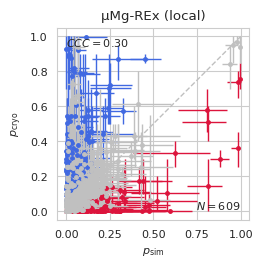

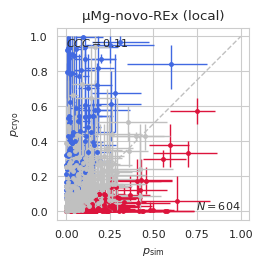

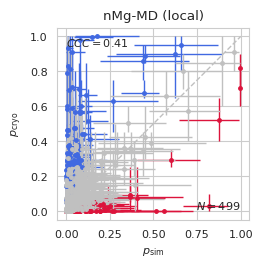

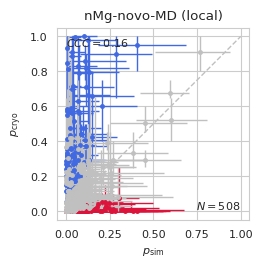

In [23]:
align = 'local'
for (method, ff) in [('replex', 'mMg_tip3p'), ('plain_md', 'nMg_tip3p')]:
    for sys in ['7ez0', '7ez0_noion']:
        fig, ax = plt.subplots(figsize=(8.7*cm, 6.5*cm))
        x = motif_summary.set_index(['motif', 'method', 'sys', 'forcefield']).loc[:, method, sys, ff]['p'].dropna()
        y = result.loc[:, method, ff, align]['best_f_mean'].dropna()
        x, y = x.align(y, join='inner')
        x_low = motif_summary.set_index(['motif', 'method', 'sys', 'forcefield']).loc[x.index, method, sys, ff]['p_low'].droplevel(['method', 'sys', 'forcefield'])
        x_high = motif_summary.set_index(['motif', 'method', 'sys', 'forcefield']).loc[x.index, method, sys, ff]['p_high'].droplevel(['method', 'sys', 'forcefield'])
        y_low  = result.loc[y.index, method, ff, align]['best_f_low'].droplevel(['method', 'forcefield', 'alignment'])
        y_high = result.loc[y.index, method, ff, align]['best_f_high'].droplevel(['method', 'forcefield', 'alignment'])
        xerr = (x - x_low).clip(0, None), (x_high - x).clip(0, None)
        yerr = (y - y_low).clip(0, None), (y_high - y).clip(0, None)
        
        ax.plot([0,1], [0,1], color='silver', ls='dashed', lw=1)

        mask = (x_low > y) & (y_high < x)
        ax.errorbar(
            x.loc[mask],
            y.loc[mask],
            xerr=[e.loc[mask] for e in xerr],
            yerr=[e.loc[mask] for e in yerr],
            fmt='.',
            elinewidth=1,
            markersize=5,
            color='crimson',
        )
        print(method, ff, sys, f"Overpredicted by simulation: {mask.sum()}/{len(mask)}")

        mask = (x_high < y) & (y_low > x)
        ax.errorbar(
            x.loc[mask],
            y.loc[mask],
            xerr=[e.loc[mask] for e in xerr],
            yerr=[e.loc[mask] for e in yerr],
            fmt='.',
            elinewidth=1,
            markersize=5,
            color='royalblue',
        )
        print(method, ff, sys, f"Underpredicted by simulation: {mask.sum()}/{len(mask)}")

        mask = ~ (((x_low > y) & (y_high < x)) | ((x_high < y) & (y_low > x)))
        ax.errorbar(
            x.loc[mask],
            y.loc[mask],
            xerr=[e.loc[mask] for e in xerr],
            yerr=[e.loc[mask] for e in yerr],
            fmt='.',
            elinewidth=1,
            markersize=5,
            color='silver',
        )
        print(method, ff, sys, f"Correctly predicted by simulation: {mask.sum()}/{len(mask)}")

        ax.set_aspect(1)
        ax.set_xlabel(r'$p_\mathrm{sim}$')
        ax.set_ylabel(r'$p_\mathrm{cryo}$')
        ax.set_title(simlabels[f'{method}_{sys}_{ff}'] + f' ({align})')
        ccc = concordance_correlation_coefficient(x, y)
        ax.text(0, 1, f'$CCC = {ccc:.2f}$', va='top')
        ax.text(1, 0, f'$N = {len(x)}$', va='bottom', ha='right')

In [24]:
noncore_resids = np.concatenate([
    list(range(63, 88+1)), 
    list(range(229, 245+1)),
    list(range(284, 295+1)),
    list(range(332, 335+1)),
    list(range(364, 402+1)),
])
motif_summary['is_core'] = motif_summary['inner_resids'].apply(
    lambda x: np.intersect1d(x, noncore_resids).size == 0
)

In [25]:
is_core = motif_summary[['motif', 'is_core']].drop_duplicates().set_index('motif')

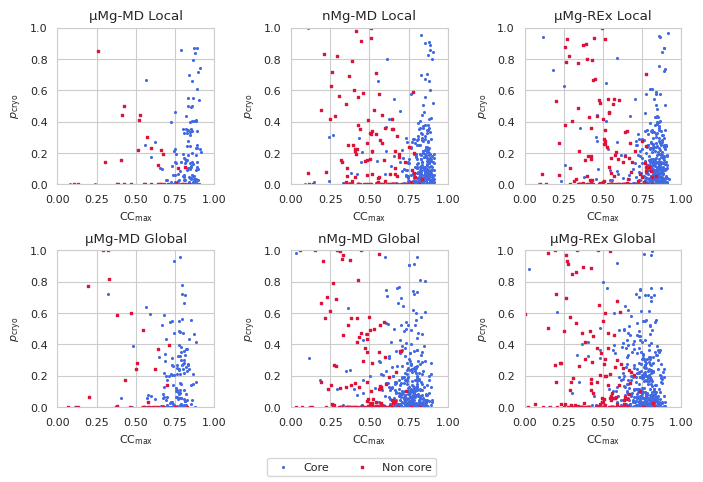

In [30]:
# Predicted p_cryo vs CCmax
result['cc_max'] = result['cc'].map(np.max)
# Core vs. helices
result['is_core'] = is_core.loc[result.index.get_level_values('motif')].to_numpy()

fig, axarr = plt.subplots(2, 3, figsize=(17.8*cm, 12*cm))

for ((method, ff), group), axes in zip(result.groupby(['method', 'forcefield']), axarr.T):
    for align, ax in zip(alignments, axes):
        
        #fig, ax = plt.subplots(figsize=(8.7*cm, 8.7*cm))
        
        ax.scatter(
            group.loc[result['is_core']].loc[:, :, :, align]['cc_max'],
            group.loc[result['is_core']].loc[:, :, :, align]['best_f_mean'],
            s=1.5,
            marker='o',
            color='royalblue',
            label='Core',
        )
        ax.scatter(
            group.loc[~result['is_core']].loc[:, :, :, align]['cc_max'],
            group.loc[~result['is_core']].loc[:, :, :, align]['best_f_mean'],
            s=1,
            marker='s',
            color='crimson',
            label='Non core',
        )
        
        ax.set_aspect(1)
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        ax.set_xlabel(r"$\mathrm{CC}_\mathrm{max}$")
        ax.set_ylabel(r"$p_\mathrm{cryo}$")
        ax.set_title(simlabels[f"{method}_7ez0_{ff}"] + f" {align.capitalize()}")
handles, labels = ax.get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncols=2)
fig.savefig(f"figures/ccmax_pcryo.pdf")


In [69]:
refs = ['7ez0', '9cbu']
sims = ['equil_7ez0_mMg_tip3p', 'equil_7ez0_noion_mMg_tip3p', 'equil_7ez0_nMg_tip3p', 'equil_7ez0_noion_nMg_tip3p', 'plain_md_7ez0_mMg_tip3p', 'plain_md_7ez0_nMg_tip3p', 'plain_md_7ez0_nMg_tip3p_soft', 'replex_7ez0_mMg_tip3p', 'plain_md_7ez0_noion_mMg_tip3p', 'plain_md_7ez0_noion_nMg_tip3p', 'replex_7ez0_noion_mMg_tip3p']
alignment = 'global'

p = motif_summary.set_index(['motif', 'sim'])[['p', 'p_low', 'p_high']].unstack('sim').swaplevel(0, 1, axis='columns').sort_index(axis=1)

p = p.loc[:, pd.IndexSlice[refs + sims]]
ndx = p.index.intersection(result.index.get_level_values(0))

p.loc[ndx, ('plain_md_7ez0_mMg_tip3p_cryo', 'p')] = result.loc[ndx, 'plain_md', 'mMg_tip3p', alignment]['best_f'].to_numpy()
p.loc[ndx, ('plain_md_7ez0_mMg_tip3p_cryo', 'p_low')] = result.loc[ndx, 'plain_md', 'mMg_tip3p', alignment]['best_f_low'].to_numpy()
p.loc[ndx, ('plain_md_7ez0_mMg_tip3p_cryo', 'p_high')] = result.loc[ndx, 'plain_md', 'mMg_tip3p', alignment]['best_f_high'].to_numpy()
p.loc[ndx, ('plain_md_7ez0_mMg_tip3p_cryo', 'cc_max')] = result.loc[ndx, 'plain_md', 'mMg_tip3p', alignment]['cc_max'].to_numpy()
p.loc[p['plain_md_7ez0_mMg_tip3p_cryo', 'cc_max'] < 0.7, pd.IndexSlice['plain_md_7ez0_mMg_tip3p_cryo', :]] = np.nan

p.loc[ndx, ('plain_md_7ez0_nMg_tip3p_cryo', 'p')] = result.loc[ndx, 'plain_md', 'nMg_tip3p', alignment]['best_f'].to_numpy()
p.loc[ndx, ('plain_md_7ez0_nMg_tip3p_cryo', 'p_low')] = result.loc[ndx, 'plain_md', 'nMg_tip3p', alignment]['best_f_low'].to_numpy()
p.loc[ndx, ('plain_md_7ez0_nMg_tip3p_cryo', 'p_high')] = result.loc[ndx, 'plain_md', 'nMg_tip3p', alignment]['best_f_high'].to_numpy()
p.loc[ndx, ('plain_md_7ez0_nMg_tip3p_cryo', 'cc_max')] = result.loc[ndx, 'plain_md', 'nMg_tip3p', alignment]['cc_max'].to_numpy()
p.loc[p['plain_md_7ez0_nMg_tip3p_cryo', 'cc_max'] < 0.7, pd.IndexSlice['plain_md_7ez0_nMg_tip3p_cryo', :]] = np.nan


p.loc[ndx, ('replex_7ez0_mMg_tip3p_cryo', 'p')] = result.loc[ndx, 'replex', 'mMg_tip3p', alignment]['best_f'].to_numpy()
p.loc[ndx, ('replex_7ez0_mMg_tip3p_cryo', 'p_low')] = result.loc[ndx, 'replex', 'mMg_tip3p', alignment]['best_f_low'].to_numpy()
p.loc[ndx, ('replex_7ez0_mMg_tip3p_cryo', 'p_high')] = result.loc[ndx, 'replex', 'mMg_tip3p', alignment]['best_f_high'].to_numpy()
p.loc[ndx, ('replex_7ez0_mMg_tip3p_cryo', 'cc_max')] = result.loc[ndx, 'replex', 'mMg_tip3p', alignment]['cc_max'].to_numpy()
p.loc[p['replex_7ez0_mMg_tip3p_cryo', 'cc_max'] < 0.7, pd.IndexSlice['replex_7ez0_mMg_tip3p_cryo', :]] = np.nan



p.drop(columns='cc_max', level=1, inplace=True)
sims.extend(['plain_md_7ez0_mMg_tip3p_cryo', 'plain_md_7ez0_nMg_tip3p_cryo', 'replex_7ez0_mMg_tip3p_cryo'])


p['Avg'] = p.loc[:, pd.IndexSlice[:, 'p']].fillna(0).mean(axis=1)

p = p.sort_values([('7ez0', 'p'), ('9cbu', 'p'), 'Avg'], ascending=False)
p = p.loc[(p['Avg'] >= 0.05) | p[('7ez0', 'p')] | p[('9cbu', 'p')]]
p = p.reset_index().rename(columns={'motif': 'Motif'})
p.index += 1
p


sim                             Motif 7ez0              9cbu               \
                                         p p_high p_low    p p_high p_low   
1    A183OP1,A184OP2,A186OP2-fac-3Oph  1.0    1.0   1.0  1.0    1.0   1.0   
2            A256OP1,U273OP1-cis-2Oph  1.0    1.0   1.0  1.0    1.0   1.0   
3            A304OP1,A306OP1-cis-2Oph  1.0    1.0   1.0  1.0    1.0   1.0   
4            A301OP1,A302OP2-cis-2Oph  1.0    1.0   1.0  1.0    1.0   1.0   
5    A184OP1,A186OP1,A187OP2-mer-3Oph  1.0    1.0   1.0  1.0    1.0   1.0   
..                                ...  ...    ...   ...  ...    ...   ...   
145                       C216OP1-Oph  NaN    NaN   NaN  NaN    NaN   NaN   
146                       G312OP2-Oph  NaN    NaN   NaN  NaN    NaN   NaN   
147                       U202OP1-Oph  NaN    NaN   NaN  NaN    NaN   NaN   
148                       U356OP2-Oph  NaN    NaN   NaN  NaN    NaN   NaN   
149                       U307OP2-Oph  NaN    NaN   NaN  NaN    NaN   NaN   

sim equil_7ez0_mMg_tip3p                     ... plain_md_7ez0_mMg_tip3p_cryo  \
                       p    p_high    p_low  ...                            p   
1                 1.0000  1.000000  1.00000  ...                         0.70   
2                 1.0000  1.000000  1.00000  ...                         0.55   
3                 0.8125  0.953041  0.59707  ...                         0.80   
4                 1.0000  1.000000  1.00000  ...                         0.50   
5                    NaN       NaN      NaN  ...                          NaN   
..                   ...       ...      ...  ...                          ...   
145                  NaN       NaN      NaN  ...                         0.00   
146                  NaN       NaN      NaN  ...                          NaN   
147                  NaN       NaN      NaN  ...                         0.25   
148                  NaN       NaN      NaN  ...                          NaN   
149                  NaN       NaN      NaN  ...                         0.00   

sim                plain_md_7ez0_nMg_tip3p_cryo                    \
    p_low   p_high                            p    p_low   p_high   
1    0.65  0.75000                         0.55  0.45000  0.70125   
2    0.40  0.70000                         0.85  0.55000  0.95000   
3    0.50  0.95000                         1.00  0.65000  1.00000   
4    0.45  0.70125                         0.55  0.39875  0.75000   
5     NaN      NaN                         0.00  0.00000  0.25000   
..    ...      ...                          ...      ...      ...   
145  0.00  0.00000                         0.25  0.05000  0.30125   
146   NaN      NaN                          NaN      NaN      NaN   
147  0.20  0.35000                         0.15  0.05000  0.20000   
148   NaN      NaN                         0.45  0.10000  0.70000   
149  0.00  0.00000                         0.00  0.00000  0.20000   

sim replex_7ez0_mMg_tip3p_cryo                      Avg  
                             p p_low   p_high            
1                         0.70  0.60  0.80000  0.634780  
2                         0.75  0.65  0.85125  0.626746  
3                         1.00  0.95  1.00000  0.611311  
4                         0.60  0.45  0.75125  0.530376  
5                         0.00  0.00  0.25000  0.190746  
..                         ...   ...      ...       ...  
145                       0.35  0.10  0.45000  0.050774  
146                       0.00  0.00  0.15000  0.050701  
147                       0.10  0.00  0.25000  0.050580  
148                        NaN   NaN      NaN  0.050357  
149                       0.45  0.25  0.65125  0.050313  

[149 rows x 50 columns]

In [95]:
#p.columns.name = 'Id'
#p.index += 1

motif_names = p['Motif']
values = p.loc[:, pd.IndexSlice[:, 'p']].droplevel(1, axis=1)
text = (
    p.loc[:, pd.IndexSlice[:, 'p']].map("{:.1f}".format).droplevel(1, axis=1)
    + " ("
    + p.loc[:, pd.IndexSlice[:, 'p_low']].map("{:.1f}".format).droplevel(1, axis=1)
    + "-"
    + p.loc[:, pd.IndexSlice[:, 'p_high']].map("{:.1f}".format).droplevel(1, axis=1)
    + ")"
).replace("nan (nan-nan)", None)

# For equil remove the CI
equil_cols = [col for col in text.columns if col.startswith('equil')]
text[equil_cols] = text[equil_cols].map(lambda s: s.split()[0] if isinstance(s, str) else None)

motif_table = motif_names.to_frame().join(text)

# Get reference MG residues
# 7ez0
u = mda.Universe(PROJECT_DIR / 'structures/7ez0/mMg_tip3p/rep00/ions2.gro')
mg_labels = motif_summary.query("sim == '7ez0'").copy()
mg_labels['mg_label'] = mg_labels['mg_indices'].apply(
    lambda x: f"$\\text{{{u.atoms[x[0]].name}}}^\\text{{{u.atoms[x[0]].resid}}}$"
)
mg_labels = mg_labels.set_index('motif')['mg_label']

motif_table['7ez0'] = motif_table['Motif'].map(
    lambda s: mg_labels.loc[s] if s in mg_labels.index else None
)

# 9cbu
u = mda.Universe(PROJECT_DIR / 'structures/9cbu/9CBU_fixed.pdb')
mg_labels = motif_summary.query("sim == '9cbu'").copy()
mg_labels['mg_label'] = mg_labels['mg_indices'].apply(
    lambda x: f"$\\text{{{u.atoms[x[0]].name}}}^\\text{{{u.atoms[x[0]].resid}}}$"
)
mg_labels = mg_labels.set_index('motif')['mg_label']

motif_table['9cbu'] = p['Motif'].map(
    lambda s: mg_labels.loc[s] if s in mg_labels.index else ""
)


motif_table['Motif'] = motif_table['Motif'].map(motif_latex_names)

motif_table = motif_table.reset_index().rename({'index':'Id'}, axis=1)
values = values.reset_index()

column_labels = [
    simlabels[col] if col in simlabels else col
    for col in motif_table.columns
]

styler = motif_table.style.set_properties(**{'background-color': '#FEFEFE', 'color': '#000000'}).background_gradient(
        axis=None, cmap="Reds", gmap=values, subset=sims
    ).highlight_null(
        color="white",
    ).highlight_null(
        color="#AAAAAA", 
        subset=['replex_7ez0_mMg_tip3p_cryo', 'plain_md_7ez0_nMg_tip3p_cryo', 'plain_md_7ez0_mMg_tip3p_cryo'],
    ).relabel_index(
        column_labels, axis=1
    ).format(
        na_rep='',
    ).hide(axis='index')

latex_code = styler.to_latex(
    column_format=f"p{{0.2cm}}p{{3.4cm}}p{{0.5cm}}p{{0.5cm}}p{{0.2cm}}p{{0.2cm}}p{{0.2cm}}p{{0.2cm}} *{{11}}{{X}}", 
    hrules=True,
    convert_css=True,
)
latex_code = latex_code.replace(r'begin{tabular}', r'begin{xltabular}{\linewidth}').replace(r'end{tabular}', r'end{xltabular}')
with open('motif_table.tex', 'w') as f:
    f.write(latex_code)
styler

/net/sbp/sbpstore2/olanguin/mg_sampling/.venv/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:479: UserWarning: 1 A^3 CRYST1 record, this is usually a placeholder. Unit cell dimensions will be set to None.
  warnings.warn(


Id,Motif,7ez0,9cbu,μMg-Eq,μMg-novo-Eq,nMg-Eq,nMg-novo-Eq,μMg-MD,nMg-MD,nMg-MD-soft,μMg-REx,μMg-novo-MD,nMg-novo-MD,μMg-novo-REx,μMg-MD + Cryo,nMg-MD + Cryo,μMg-REx + Cryo
1,"$\text{A}^\text{183}_\text{OP1}$,$\text{A}^\text{184}_\text{OP2}$,$\text{A}^\text{186}_\text{OP2}$-\textit{fac}-3$\text{O}_\text{ph}$",$\text{MG}^\text{505}$,$\text{MG}^\text{502}$,1.0,,1.0,,1.0 (1.0-1.0),1.0 (1.0-1.0),1.0 (1.0-1.0),1.0 (1.0-1.0),,0.1 (0.0-0.4),0.1 (0.0-0.3),0.7 (0.7-0.8),0.6 (0.5-0.7),0.7 (0.6-0.8)
2,"$\text{A}^\text{256}_\text{OP1}$,$\text{U}^\text{273}_\text{OP1}$-\textit{cis}-2$\text{O}_\text{ph}$",$\text{MG}^\text{511}$,$\text{MG}^\text{507}$,1.0,,1.0,,1.0 (1.0-1.0),0.9 (0.6-1.0),0.7 (0.5-0.9),1.0 (1.0-1.0),,0.0 (0.0-0.0),0.3 (0.1-0.5),0.6 (0.4-0.7),0.9 (0.6-1.0),0.8 (0.7-0.9)
3,"$\text{A}^\text{304}_\text{OP1}$,$\text{A}^\text{306}_\text{OP1}$-\textit{cis}-2$\text{O}_\text{ph}$",$\text{MG}^\text{526}$,$\text{MG}^\text{508}$,0.8,0.1,0.9,,0.5 (0.2-0.8),0.6 (0.3-0.9),0.6 (0.3-0.9),1.0 (0.9-1.0),,0.3 (0.1-0.5),0.3 (0.1-0.5),0.8 (0.5-1.0),1.0 (0.7-1.0),1.0 (1.0-1.0)
4,"$\text{A}^\text{301}_\text{OP1}$,$\text{A}^\text{302}_\text{OP2}$-\textit{cis}-2$\text{O}_\text{ph}$",$\text{MG}^\text{519}$,$\text{MG}^\text{504}$,1.0,,1.0,,0.7 (0.5-1.0),0.7 (0.4-0.9),0.4 (0.2-0.7),1.0 (0.9-1.0),,,,0.5 (0.5-0.7),0.6 (0.4-0.8),0.6 (0.5-0.8)
5,"$\text{A}^\text{184}_\text{OP1}$,$\text{A}^\text{186}_\text{OP1}$,$\text{A}^\text{187}_\text{OP2}$-\textit{mer}-3$\text{O}_\text{ph}$",$\text{MG}^\text{504}$,$\text{MG}^\text{503}$,,,,0.4,,,0.1 (0.0-0.2),,,0.4 (0.1-0.7),0.2 (0.1-0.4),,0.0 (0.0-0.2),0.0 (0.0-0.2)
6,$\text{U}^\text{259}_\text{OP1}$-$\text{O}_\text{ph}$,$\text{MG}^\text{517}$,,0.2,0.2,0.8,0.5,0.7 (0.5-0.8),1.0 (0.9-1.0),0.8 (0.6-1.0),0.9 (0.9-1.0),0.2 (0.0-0.5),0.8 (0.5-0.9),0.6 (0.3-0.8),0.5 (0.2-0.7),0.8 (0.5-0.9),0.8 (0.6-1.0)
7,$\text{U}^\text{305}_\text{OP1}$-$\text{O}_\text{ph}$,$\text{MG}^\text{518}$,,1.0,0.1,1.0,0.1,0.8 (0.5-0.9),0.7 (0.4-0.9),0.5 (0.3-0.7),0.4 (0.3-0.6),0.3 (0.1-0.6),0.4 (0.2-0.7),0.3 (0.1-0.4),1.0 (0.7-1.0),1.0 (0.5-1.0),0.7 (0.3-0.9)
8,"$\text{U}^\text{307}_\text{OP2}$,$\text{A}^\text{308}_\text{OP2}$-\textit{cis}-2$\text{O}_\text{ph}$",$\text{MG}^\text{527}$,,1.0,,1.0,0.1,1.0 (1.0-1.0),0.4 (0.2-0.7),0.4 (0.2-0.7),0.3 (0.1-0.5),,0.1 (0.0-0.3),0.1 (0.0-0.3),1.0 (0.8-1.0),1.0 (0.6-1.0),1.0 (0.7-1.0)
9,"$\text{A}^\text{172}_\text{OP2}$,$\text{A}^\text{173}_\text{OP2}$-\textit{cis}-2$\text{O}_\text{ph}$",$\text{MG}^\text{523}$,,1.0,,1.0,,0.9 (0.7-1.0),0.5 (0.2-0.6),0.5 (0.3-0.6),0.4 (0.4-0.5),,0.0 (0.0-0.1),0.2 (0.1-0.3),0.7 (0.6-0.8),1.0 (0.8-1.0),1.0 (0.9-1.0)
10,"$\text{G}^\text{257}_\text{OP1}$,$\text{U}^\text{258}_\text{OP2}$,$\text{C}^\text{260}_\text{O2}$,$\text{U}^\text{305}_\text{OP2}$-\underline{Cis}-3$\text{O}_\text{ph}$$\text{O}_\text{b}$",$\text{MG}^\text{515}$,,1.0,,0.9,,0.8 (0.5-1.0),0.3 (0.2-0.5),0.4 (0.2-0.7),1.0 (0.9-1.0),,,,0.4 (0.2-0.5),0.4 (0.2-0.5),0.5 (0.4-0.7)


In [86]:
df

,motif,frames_present,frames_absent,map_present,map_absent,sim,method,system,forcefield,replicate,repid,alignment
0,A103OP1-Oph,"[719, 856, 862, 865, 874, 875, 881, 891, 892, ...","[0, 92, 100, 140, 148, 153, 156, 158, 160, 166...",<mg_sampling.density.grid.SparseGrid object at...,<mg_sampling.density.grid.SparseGrid object at...,replex_7ez0_mMg_tip3p,replex,7ez0,mMg_tip3p,0,0,local
1,A103OP2-Oph,"[92, 100, 140, 148, 153, 156, 158, 160, 166, 1...","[0, 439, 476, 533, 540, 549, 584, 606, 643, 71...",<mg_sampling.density.grid.SparseGrid object at...,<mg_sampling.density.grid.SparseGrid object at...,replex_7ez0_mMg_tip3p,replex,7ez0,mMg_tip3p,0,0,local
2,A104OP1-Oph,[],"[0, 92, 100, 140, 148, 153, 156, 158, 160, 166...",<mg_sampling.density.grid.SparseGrid object at...,<mg_sampling.density.grid.SparseGrid object at...,replex_7ez0_mMg_tip3p,replex,7ez0,mMg_tip3p,0,0,local
3,A104OP2-Oph,"[140, 148, 153, 156, 158, 160, 166, 168, 171, ...","[0, 92, 100, 172, 174, 178, 179, 181, 190, 191...",<mg_sampling.density.grid.SparseGrid object at...,<mg_sampling.density.grid.SparseGrid object at...,replex_7ez0_mMg_tip3p,replex,7ez0,mMg_tip3p,0,0,local
4,A105OP1-Oph,[],"[0, 92, 100, 140, 148, 153, 156, 158, 160, 166...",<mg_sampling.density.grid.SparseGrid object at...,<mg_sampling.density.grid.SparseGrid object at...,replex_7ez0_mMg_tip3p,replex,7ez0,mMg_tip3p,0,0,local
...,...,...,...,...,...,...,...,...,...,...,...,...
648,G313O2'-Or,[],"[0, 24, 48, 72, 96, 120, 144, 168, 192, 216, 2...",<mg_sampling.density.grid.SparseGrid object at...,<mg_sampling.density.grid.SparseGrid object at...,plain_md_7ez0_noion_nMg_tip3p,plain_md,7ez0_noion,nMg_tip3p,0,7,global
649,G96N7-Nb,[],"[0, 24, 48, 72, 96, 120, 144, 168, 192, 216, 2...",<mg_sampling.density.grid.SparseGrid object at...,<mg_sampling.density.grid.SparseGrid object at...,plain_md_7ez0_noion_nMg_tip3p,plain_md,7ez0_noion,nMg_tip3p,0,7,global
650,U277O4-Ob,[],"[0, 24, 48, 72, 96, 120, 144, 168, 192, 216, 2...",<mg_sampling.density.grid.SparseGrid object at...,<mg_sampling.density.grid.SparseGrid object at...,plain_md_7ez0_noion_nMg_tip3p,plain_md,7ez0_noion,nMg_tip3p,0,7,global
651,U326O4-Ob,[],"[0, 24, 48, 72, 96, 120, 144, 168, 192, 216, 2...",<mg_sampling.density.grid.SparseGrid object at...,<mg_sampling.density.grid.SparseGrid object at...,plain_md_7ez0_noion_nMg_tip3p,plain_md,7ez0_noion,nMg_tip3p,0,7,global


In [84]:
len(column_labels)

18

In [ ]:
#p.columns.name = 'Id'
#p.index += 1

motif_names = p['Motif']
values = p.loc[:, pd.IndexSlice[:, 'p']].droplevel(1, axis=1)
text = (
    p.loc[:, pd.IndexSlice[:, 'p']].map("{:.1f}".format).droplevel(1, axis=1)
    + " ("
    + p.loc[:, pd.IndexSlice[:, 'p_low']].map("{:.1f}".format).droplevel(1, axis=1)
    + "-"
    + p.loc[:, pd.IndexSlice[:, 'p_high']].map("{:.1f}".format).droplevel(1, axis=1)
    + ")"
).replace("nan (nan-nan)", None)

motif_table = motif_names.to_frame().join(text)

# Get reference MG residues
# 7ez0
u = mda.Universe(PROJECT_DIR / 'structures/7ez0/mMg_tip3p/rep00/ions2.gro')
mg_labels = motif_summary.query("sim == '7ez0'").copy()
mg_labels['mg_label'] = mg_labels['mg_indices'].apply(
    lambda x: f"$\\text{{{u.atoms[x[0]].name}}}^\\text{{{u.atoms[x[0]].resid}}}$"
)
mg_labels = mg_labels.set_index('motif')['mg_label']

motif_table['7ez0'] = motif_table['Motif'].map(
    lambda s: mg_labels.loc[s] if s in mg_labels.index else None
)

# 9cbu
u = mda.Universe(PROJECT_DIR / 'structures/9cbu/9CBU_fixed.pdb')
mg_labels = motif_summary.query("sim == '9cbu'").copy()
mg_labels['mg_label'] = mg_labels['mg_indices'].apply(
    lambda x: f"$\\text{{{u.atoms[x[0]].name}}}^\\text{{{u.atoms[x[0]].resid}}}$"
)
mg_labels = mg_labels.set_index('motif')['mg_label']

motif_table['9cbu'] = p['Motif'].map(
    lambda s: mg_labels.loc[s] if s in mg_labels.index else ""
)


motif_table['Motif'] = motif_table['Motif'].map(motif_latex_names)

motif_table = motif_table.reset_index().rename({'index':'Id'}, axis=1)
values = values.reset_index()

column_labels = [
    simlabels[col] if col in simlabels else col
    for col in motif_table.columns
]

styler = motif_table.style.set_properties(**{'background-color': '#FEFEFE', 'color': '#000000'}).background_gradient(
        axis=None, cmap="Reds", gmap=values, subset=sims
    ).highlight_null(
        color="white",
    ).highlight_null(
        color="#AAAAAA", 
        subset=['replex_7ez0_mMg_tip3p_cryo', 'plain_md_7ez0_nMg_tip3p_cryo'],
    ).relabel_index(
        column_labels, axis=1
    ).format(
        na_rep='',
    ).hide(axis='index')

latex_code = styler.to_latex(
    column_format=f"p{{0.5cm}}p{{4.2cm}}p{{0.8cm}}p{{0.8cm}} *{{{len(motif_table.columns)-3}}}{{X}}\label{{stable:motif_table}}", # 'X' è tipico di xltabular/tabularx per colonne estensibili
    hrules=True,
    convert_css=True,
)
latex_code = latex_code.replace(r'begin{tabular}', r'begin{xltabular}{\linewidth}').replace(r'end{tabular}', r'end{xltabular}')
with open('motif_table.tex', 'w') as f:
    f.write(latex_code)
styler

Index(['motif', 'frames_present', 'frames_absent', 'map_present', 'map_absent',
       'sim', 'method', 'system', 'forcefield', 'replicate', 'repid',
       'alignment'],
      dtype='object')

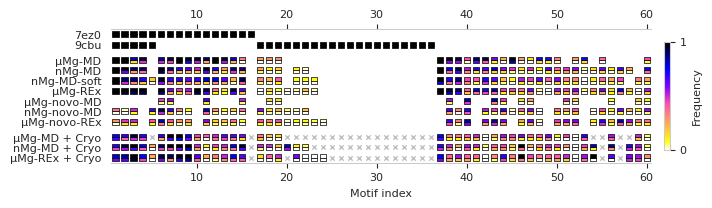

In [131]:
from matplotlib.markers import MarkerStyle

sims = [sim for sim in sims if not sim.startswith('equil')]
n_motifs = 60
n_sims = len(refs + sims)
ticklabels = refs + [simlabels[sim] for sim in sims]

fig, ax = plt.subplots(figsize=(17.8*cm,5*cm))

ax.invert_yaxis()
ax.grid(None)

p_ = p.loc[:, pd.IndexSlice[:, 'p']].droplevel(1, axis=1).iloc[:n_motifs][refs + sims]
p_low = p.loc[:, pd.IndexSlice[:, 'p_low']].droplevel(1, axis=1).iloc[:n_motifs][refs + sims]
p_high = p.loc[:, pd.IndexSlice[:, 'p_high']].droplevel(1, axis=1).iloc[:n_motifs][refs + sims]

for col in p_.columns:
    if p_[col].dtype == 'O':
        p_[col] = p_[col].map(lambda s: 1 if s else None)

#group = p_.index[0][0]
y_range = np.arange(n_sims).astype(float)
y_range[-3:] += 0.5
y_range[:2] -= 0.5
for i, (ndx, row_low) in enumerate(p_low.iterrows()):
    ax.scatter(1 + np.ones(n_sims) * i, y_range, c=row_low, cmap='gnuplot2_r', edgecolors='k', s=20, marker=MarkerStyle('s', fillstyle='bottom'), vmin=0, vmax=1, clip_on=False, linewidths=0.5)
    ax.scatter(1 + np.ones(n_sims)[-3:] * i, y_range[-3:], marker='x', facecolor='silver', lw=1, s=10, zorder=-10)
for i, (ndx, row_high) in enumerate(p_high.iterrows()):
    ax.scatter(1 + np.ones(n_sims) * i, y_range, c=row_high, cmap='gnuplot2_r', edgecolors='k', s=20, marker=MarkerStyle('s', fillstyle='top'), vmin=0, vmax=1, clip_on=False, linewidths=0.5)



ax.tick_params(top=True, labeltop=True, bottom=True, labelbottom=True)
ax.spines[['left', 'right']].set_visible(False)
ax.set_yticks(y_range, ticklabels)
#ax.set_xticks(range(len(p_)), motif_latex.loc[p_.index.get_level_values('motif')], rotation=45)

ax.set_xlabel('Motif index')
ax.set_xlim(0.5, n_motifs+0.5)
ax.set_ylim(y_range[-1]+0.5, y_range[0]-0.5)

cax = plt.colorbar(ScalarMappable(norm=Normalize(0, 1), cmap='gnuplot2_r'), ax=ax, pad=0.02, fraction=0.01, label='Frequency')
from matplotlib.ticker import StrMethodFormatter
cax.ax.set_yticks([0, 1])
fig.savefig('figures/motif_analysis.pdf')

In [97]:
ref_map = (ref_hmap_A + ref_hmap_B)/2

In [123]:
# Highlighted cases: extract data for figure
os.makedirs('motif_highlight', exist_ok=True)

motifs = [
    "G257OP1,U258OP2,C260O2,U305OP2-Cis-3OphOb",
    "G257OP1,U258OP2,U305OP2-mer-3Oph",
    "A184OP1,A186OP1,A187OP2-mer-3Oph",
    "A184OP1,A186OP1,A187OP2,G188OP2-Trans-4Oph",
]

ref = mda.Universe(PROJECT_DIR / "structures/9CBU_fixed.pdb")

for motif in motifs:
    data = result.loc[motif, 'replex', 'mMg_tip3p', alignment]
    map_present = data['map_present']
    map_absent = data['map_absent']
    map_ref = ref_map.to_sparse(vox_indices=map_present.vox_indices)
    # Linfit
    lr = linregress(map_present.data, map_ref.data)
    map_present = lr.slope * map_present + lr.intercept
    lr = linregress(map_absent.data, map_ref.data)
    map_absent = lr.slope * map_absent + lr.intercept
    os.makedirs(f'motif_highlight/{motif}', exist_ok=True)
    map_present.to_dense().astype(np.float32).export(f'motif_highlight/{motif}/present.mrc')
    map_absent.to_dense().astype(np.float32).export(f'motif_highlight/{motif}/absent.mrc')
    best_f = data['best_f']
    map_mixture = map_present * best_f + map_absent * (1 - best_f)
    map_mixture.to_dense().astype(np.float32).export(f'motif_highlight/{motif}/best_mixture.mrc')
    map_ref.to_dense().astype(np.float32).export(f'motif_highlight/{motif}/ref_map.mrc')
    
    for what in ('present', 'absent'):
        done = False
        for ndx, row in df.set_index('motif').loc[motif].iterrows():
            rep = row['replicate']
            i = row['repid']
            sys = row['system']
            for frame in row[f'frames_{what}']:
                try:
                    motif_info = motif_summary.set_index(['motif', 'sim']).loc[motif, f"replex_{sys}_mMg_tip3p"]
                except KeyError as e:
                    break
                u = mda.Universe(
                    PROJECT_DIR / f'replex/{sys}/mMg_tip3p/replicate{rep}/rep{i+8*rep:02d}/input.gro',
                    PROJECT_DIR / f'replex/{sys}/mMg_tip3p/replicate{rep}/rep{i+8*rep:02d}/run.xtc',
                )
                standardize_names(u)
                u.trajectory[frame]
                rna = u.select_atoms('nucleic and not type H')
                unwrap_sequential(rna)
                wrap_around_atomgroup(u.atoms, rna.select_atoms("name P"))
                inner_resnames, inner_resids, inner_names = motif_info[['inner_resnames', 'inner_resids', 'inner_names']]
                motif_sel = u.select_atoms(
                    *(f"resname {resname} and resid {resid} and name {name}"
                    for resname, resid, name in zip(inner_resnames, inner_resids, inner_names)
                    )
                )
                u_sel = rna.select_atoms("group motif_sel or around 10 group motif_sel", motif_sel=motif_sel)
                ref_sel = ref.select_atoms(
                    *(f"resname {a.resname} and resid {a.resid} and name {a.name}"
                    for a in u_sel)
                )
                assert len(u_sel) == len(ref_sel)
                alignto(u_sel, ref_sel)
                u.atoms.write(f"motif_highlight/{motif}/{what}.pdb")
                done = True
                break
            if done: 
                break



/net/sbp/sbpstore2/olanguin/mg_sampling/.venv/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:479: UserWarning: 1 A^3 CRYST1 record, this is usually a placeholder. Unit cell dimensions will be set to None.
  warnings.warn(
/net/sbp/sbpstore2/olanguin/mg_sampling/.venv/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:1282: UserWarning: Found no information for attr: 'altLocs' Using default value of ' '
  warnings.warn(
/net/sbp/sbpstore2/olanguin/mg_sampling/.venv/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:1282: UserWarning: Found no information for attr: 'icodes' Using default value of ' '
  warnings.warn(
/net/sbp/sbpstore2/olanguin/mg_sampling/.venv/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:1282: UserWarning: Found no information for attr: 'chainIDs' Using default value of ''
  warnings.warn(
/net/sbp/sbpstore2/olanguin/mg_sampling/.venv/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:1282: UserWarning: Found no informa

/tmp/ipykernel_674/3874068143.py:23: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig_legend.show()


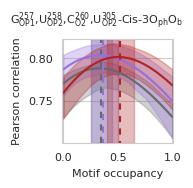

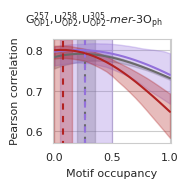

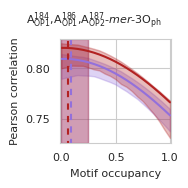

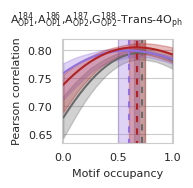

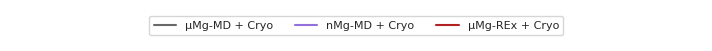

In [122]:
for motif in motifs:
    fig, ax = plt.subplots(figsize=(4.5*cm, 4.5*cm))
    for i, (method, ff) in enumerate([('plain_md', 'mMg_tip3p'), ('plain_md', 'nMg_tip3p'), ('replex', 'mMg_tip3p')]):
        sim = f'{method}_7ez0_{ff}_cryo'
        data = result.loc[motif, method, ff, alignment]
        if data.isna().any():
            continue
        ax.plot(f_range, data['cc'], color=simcolors[sim], label=simlabels[sim])
        ax.fill_between(f_range, data['cc_low'], data['cc_high'], color=simcolors[sim], alpha=0.3)
        ax.axvline(data['best_f_mean'], color=simcolors[sim], ls=(i, (3, 3)))
        ax.axvspan(data['best_f_low'], data['best_f_high'], color=simcolors[sim], alpha=0.3)
    ax.set_xlim(-0.01, 1.01)
    ax.set_ylabel("Pearson correlation")
    ax.set_xlabel("Motif occupancy")
    #ax.legend(bbox_to_anchor=(1, 1), loc="lower right")
    fig.suptitle(motif_mathtex_names.loc[motif], fontsize=8)
    fig.savefig(f"motif_highlight/{motif}/{motif}_best_f.pdf")

handles, labels = ax.get_legend_handles_labels()
fig_legend, ax_legend = plt.subplots(figsize=(17.8*cm, 1*cm))
ax_legend.axis('off')
ax_legend.legend(handles, labels, ncols=len(labels), loc='center')
fig_legend.show()
fig_legend.savefig(f"motif_highlight/legend.pdf")

In [ ]:
# Total number of significant (> 5%) motifs
x = motif_summary.query('p > 0.05').groupby(['sim', 'n_inner'])['p'].count().unstack().fillna(0).astype(int).rename(index=simlabels)
x = pd.concat([x, x.sum(axis=1).rename('')], keys=(r'Denticity', 'Tot'), axis=1)
x.index.name = None
x.columns.name = '$n_\mathrm{inner}$'
styler = x.style.background_gradient(cmap='Reds')


latex_code = styler.to_latex(
    column_format=f"l{'r' * len(x.columns)}",
    hrules=True,
    convert_css=True,
)
with open('motif_count.tex', 'w') as f:
    f.write(latex_code)

styler

In [102]:
# Number of motifs recovered/retained from PDBs
motif_7ez0 = motif_summary.query('sim == "7ez0"')['motif']
motif_9cbu = motif_summary.query('sim == "9cbu"')['motif']

x = motif_summary.query('p > 0.05').groupby(['sim', 'n_inner']).apply(
    lambda x: pd.Series({
        '7ez0': np.isin(x['motif'], motif_7ez0).sum(),
        '9cbu': np.isin(x['motif'], motif_9cbu).sum(),
    })
)
x = x.unstack().fillna(0).astype(int)
x = x.loc[:, ~(x == 0).all()]
x.index.name = None
xsum = x.T.groupby(level=0).sum().T
xsum.columns = pd.MultiIndex.from_product([xsum.columns, ['Tot']])
x = x.join(xsum).sort_index(axis=1).rename(simlabels)
x['7ez0'] = x['7ez0'].astype(str) + '/' + x['7ez0'].loc['7ez0'].astype(str)
x['9cbu'] = x['9cbu'].astype(str) + '/' + x['9cbu'].loc['9cbu'].astype(str)

styler = x.style.background_gradient(cmap='Reds', gmap=x.map(lambda v: int(v.split('/')[0])), axis=None)

latex_code = styler.to_latex(
    column_format=f"l{'r' * len(x.columns)}",
    hrules=True,
    convert_css=True,
)
#latex_code = latex_code.replace(r'begin{tabular}', r'begin{xltabular}{\textwidth}').replace(r'end{tabular}', r'end{xltabular}')
with open('motif_recovery.tex', 'w') as f:
    f.write(latex_code)

styler

/tmp/ipykernel_674/3591111778.py:5: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  x = motif_summary.query('p > 0.05').groupby(['sim', 'n_inner']).apply(


In [ ]:
def plot_map_slice(
    grid: Grid,
    func: str = "imshow",
    plane="xy",
    depth=0.5,
    depth_mode="fraction",
    thickness=0,
    ax=None,
    **kwargs,
):
    if ax is None:
        ax = plt.gca()

    if isinstance(func, str):
        func = getattr(ax, func)

    x_axis, y_axis = ["xyz".index(dim) for dim in plane]
    depth_axis = ({0, 1, 2} - set((x_axis, y_axis))).pop()
    midpoints = grid.midpoints[depth_axis]
    dx = grid.delta[depth_axis]
    x_edges, y_edges = grid.edges[x_axis], grid.edges[y_axis]
    extent = [*x_edges[[0, -1]], *y_edges[[0, -1]]]
    z_edges = grid.edges[depth_axis]

    if depth_mode == "fraction":
        k = int(depth * len(midpoints))
        dk = int(thickness * len(midpoints))
    elif depth_mode == "index":
        k = int(depth)
        dk = int(thickness)
    elif depth_mode == "coord":
        k = int(np.searchsorted(midpoints, depth, side="left"))
        dk = int(np.searchsorted(midpoints - midpoints[0], thickness, side="left"))

    if thickness == 0:
        s = tuple(slice(None) if d in (x_axis, y_axis) else k for d in (0, 1, 2))
        img = grid.grid[s].T
    else:
        k_min = max(k-dk, 0)
        k_max = min(k+dk, len(midpoints))
        s = tuple(slice(None) if d in (x_axis, y_axis) else slice(k_min, k_max) for d in (0, 1, 2))
        img = grid.grid[s].mean(axis=depth_axis).T

    out = func(img, origin="lower", extent=extent, **kwargs)

    ax.set_xlabel("xyz"[x_axis])
    ax.set_ylabel("xyz"[y_axis])

    return out

In [ ]:
results

In [ ]:
df = []
for method, sys, ff in [
    ('replex', '7ez0', 'mMg_tip3p'),
    ('replex', '7ez0_noion', 'mMg_tip3p'),
    ('plain_md', '7ez0', 'nMg_tip3p'),
    ('plain_md', '7ez0_noion', 'nMg_tip3p'),
]:
    outpath = PROJECT_DIR / f'density/{method}_{sys}_{ff}/{alignment}/individual'
    df.append(pd.read_pickle(outpath / "results.pkl").assign(method=method, sys=sys, ff=ff))
results = pd.concat(df)

In [ ]:
motifs_summary

In [ ]:
from matplotlib.colors import Normalize, CenteredNorm

motifs_summary = pd.concat([
    pd.read_parquet(PROJECT_DIR / f'replex/{sys}/mMg_tip3p/MG_motifs_summary_lambda0.parquet').assign(method='replex', sys=sys, ff='mMg_tip3p')
    for sys in ('7ez0', '7ez0_noion')
])
motifs_summary = pd.concat([
    motifs_summary,
    pd.concat([
        pd.read_parquet(PROJECT_DIR / f'plain_md/{sys}/nMg_tip3p/MG_motifs_summary.parquet').assign(method='plain_md', sys=sys, ff='nMg_tip3p')
        for sys in ('7ez0', '7ez0_noion')
    ]),
])
motifs_summary = pd.concat([
    motifs_summary,
    pd.read_parquet(PROJECT_DIR / f'structures/7ez0/mMg_tip3p/MG_motifs_summary.parquet').assign(sys='7ez0_PDB')
])

for motif, group in results.groupby('motif'):
    data = motifs_summary.query('motif == @motif').iloc[0]
    inner_names, inner_resids, inner_resnames = data[['inner_names', 'inner_resids', 'inner_resnames']]
    
    ref_motif = ref.select_atoms(*[
        f"name {name} and resid {resid} and resname {resname}" 
        for name, resid, resname in zip(inner_names, inner_resids, inner_resnames)
    ])
    
    fig, axarr = plt.subplots(ncols=5, figsize=(20, 4))

    res = group.iloc[0]

    for _map, label, ax in zip((res['map_present'], res['map_absent'], res['map_present'] - res['map_absent'], res['map_ref']), ('Present', 'Absent', 'Δ(Present - Absent)', 'Ref'), axarr[:4]):

        x0, y0, z0 = ref_motif.center_of_geometry()

        cmap = 'coolwarm' if label == 'Δ(Present - Absent)' else 'gnuplot2'
        norm = CenteredNorm() if label == 'Δ(Present - Absent)' else Normalize()
        plot_map_slice(_map.to_dense(), depth=x0, plane='yz', depth_mode='coord', thickness=20, ax=ax, cmap=cmap, norm=norm)
        ax.set_xlim(y0 - 10, y0 + 10)
        ax.set_ylim(z0 - 10, z0 + 10)
        ax.set_title(label)
        ax.grid(False)
        
    ax = axarr[4]

    for _, res in group.iterrows():
        method = res['method']
        sys = res['sys']
        ff = res['ff']
        sim = f"{method}_{sys}_{ff}"
        data = motifs_summary.query('motif == @motif and method == @method and sys == @sys and ff == @ff').iloc[0]
        ax.axvline(data['p'], color=simcolors[sim], ls='dashed', label=sim)
        ax.axvspan(data['p_low'], data['p_high'], color='gray', alpha=0.2)
        line, = ax.plot(f_range, res['cc_mean'], color=simcolors[sim])
        ax.fill_between(f_range, res['cc_low'], res['cc_high'], alpha=0.2, color=line.get_color())
        ax.axvline(res['best_frac_mean'], color=line.get_color())
        ax.axvspan(res['best_frac_low'], res['best_frac_high'], color=line.get_color(), alpha=0.2)

    data = motifs_summary.query('motif == @motif and sys == "7ez0_PDB"')
    if len(data):
        ax.axvline(data.iloc[0]['p'], color='black', ls='solid', label='PDB')
    else:
        ax.axvline(0, color='black', ls='solid', label='PDB')
    
    ax.set_xlabel("Fraction of motif present")
    ax.set_ylabel("CC")
    ax.legend(frameon=False)

    ax.set_ylim(0.28, 0.95)
    fig.suptitle(f"{res['motif']} {res['alignment']} alignment")
    plt.show()